# SAR → structure → optical color: MRSHaze testing

Enable GPU and Internet, attach MRSHaze, and attach the **saved output of the training notebook**. This notebook clones the same GitHub repository and evaluates the held-out test split. Update the repository URL and checkpoint mount path as needed. Use the same source revision as training when possible.


In [1]:
from pathlib import Path
import os
import subprocess
import sys

# Update this if the new repository has a different owner/name.
REPO_URL = "https://github.com/sumire25/SARguidedRSID.git"
REPO_REF = None  # Optional branch/tag. Leave None for the repository default.
REPO_DIR = Path("/kaggle/working/SARguidedRSID")
DATA_ROOT = Path("/kaggle/input/datasets/markosumire/mrshaze/MRSHaze")

if not (REPO_DIR / ".git").is_dir():
    command = ["git", "clone", "--depth", "1"]
    if REPO_REF:
        command += ["--branch", REPO_REF]
    subprocess.run(command + [REPO_URL, str(REPO_DIR)], check=True)
os.chdir(REPO_DIR)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
revision = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()
print("Source revision:", revision)
assert DATA_ROOT.is_dir(), f"Mount MRSHaze and update DATA_ROOT: {DATA_ROOT}"

import torch
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Enable a GPU in Kaggle Settings before full training/testing."
print("GPU:", torch.cuda.get_device_name(0))


Cloning into '/kaggle/working/SARguidedRSID'...


Source revision: 7a071978ed440b2f439451fbf020cca9165490f5
PyTorch: 2.11.0+cu128
CUDA: True
GPU: Tesla T4


In [2]:
WEIGHTS = Path("/kaggle/input/notebooks/markosumire/train-kaggle/runs/sar_gray_color/last.pt")
RESULT_DIR = Path("/kaggle/working/results/sar_gray_color")
TILE_SIZE = 0  # Full frame. If necessary, use 256 with OVERLAP=32 to reduce GPU memory.
OVERLAP = 32
assert WEIGHTS.is_file(), f"Attach the training notebook output and update WEIGHTS: {WEIGHTS}"

from graytocolor.runtime import load_checkpoint
checkpoint = load_checkpoint(WEIGHTS)
print("Training epoch:", checkpoint["epoch"], "phase:", checkpoint["phase"])
print("Training mode:", checkpoint["config"]["mode"])
print("Model:", checkpoint["config"]["model"])


Training epoch: 6 phase: joint
Training mode: e2e
Model: {'width': 32, 'depth': 2, 'sar_channels': 1, 'use_sar': True, 'use_structure_features': True}


## Run all test triplets

The model consumes only hazy RGB and SAR. GT is loaded exclusively for metrics. RGB, recovered grayscale, and learned fusion-region maps are saved separately. Fusion maps are **not physical transmission maps**.

Metrics are computed per image at full native resolution, without border shaving, on float RGB in [0,1] before PNG quantization. Tiled and full-frame results can differ because attention uses global channel correlations; report the inference setting when comparing methods.


In [3]:
command = [
    sys.executable, "-u", "infer.py",
    "--weights", str(WEIGHTS),
    "--data-root", str(DATA_ROOT),
    "--split", "test",
    "--output-dir", str(RESULT_DIR),
    "--device", "cuda",
    "--tile-size", str(TILE_SIZE),
    "--overlap", str(OVERLAP),
    "--save-aux",
]
subprocess.run(command, cwd=REPO_DIR, check=True)


1/2000: {'id': '00001', 'inference_seconds': 1.6131938510000055, 'psnr': 30.064098358154297, 'ssim': 0.9678136110305786, 'mae': 0.014849236235022545, 'sam_deg': 2.9180595874786377, 'ergas': 23.320886611938477, 'gray_psnr': 29.9278621673584, 'gray_ssim': 0.9730114340782166, 'hazy_psnr': 22.67263412475586, 'hazy_ssim': 0.8569850921630859, 'hazy_mae': 0.049555592238903046, 'hazy_sam_deg': 7.7555389404296875, 'hazy_ergas': 54.59894561767578}
100/2000: {'id': '00100', 'inference_seconds': 0.16575363000004018, 'psnr': 23.89858055114746, 'ssim': 0.9091084003448486, 'mae': 0.0497245192527771, 'sam_deg': 5.376180648803711, 'ergas': 28.039220809936523, 'gray_psnr': 24.132156372070312, 'gray_ssim': 0.9201074838638306, 'hazy_psnr': 15.430584907531738, 'hazy_ssim': 0.7571751475334167, 'hazy_mae': 0.1532215178012848, 'hazy_sam_deg': 6.203225135803223, 'hazy_ergas': 73.5770492553711}
200/2000: {'id': '00200', 'inference_seconds': 0.168405966000023, 'psnr': 21.195133209228516, 'ssim': 0.93546068668365

CompletedProcess(args=['/usr/bin/python3', '-u', 'infer.py', '--weights', '/kaggle/input/notebooks/markosumire/train-kaggle/runs/sar_gray_color/last.pt', '--data-root', '/kaggle/input/datasets/markosumire/mrshaze/MRSHaze', '--split', 'test', '--output-dir', '/kaggle/working/results/sar_gray_color', '--device', 'cuda', '--tile-size', '0', '--overlap', '32', '--save-aux'], returncode=0)

In [4]:
import json
import pandas as pd
summary = json.loads((RESULT_DIR / "summary.json").read_text())
print(json.dumps(summary, indent=2))
display(pd.read_csv(RESULT_DIR / "per_image.csv").head())


{
  "images": 2000,
  "split": "test",
  "checkpoint": "/kaggle/input/notebooks/markosumire/train-kaggle/runs/sar_gray_color/last.pt",
  "checkpoint_epoch": 6,
  "mode": "e2e",
  "tile_size": 0,
  "overlap": 32,
  "amp": false,
  "limited_run": false,
  "metric_protocol": "mean per-image; float RGB [0,1] before PNG quantization; no border shaving; Gaussian valid SSIM; RGB SAM degrees; ERGAS ratio=1",
  "mean": {
    "inference_seconds": 0.17229861773150043,
    "psnr": 23.298342529296875,
    "ssim": 0.8340893117189407,
    "mae": 0.055805956536903976,
    "sam_deg": 4.201221604168415,
    "ergas": 35.93510789299011,
    "gray_psnr": 23.219630271911623,
    "gray_ssim": 0.8351081155091524,
    "hazy_psnr": 15.975462037324906,
    "hazy_ssim": 0.6540748479440809,
    "hazy_mae": 0.1388708988581784,
    "hazy_sam_deg": 7.070366305530071,
    "hazy_ergas": 94.65909909272195
  }
}


,id,inference_seconds,psnr,ssim,mae,sam_deg,ergas,gray_psnr,gray_ssim,hazy_psnr,hazy_ssim,hazy_mae,hazy_sam_deg,hazy_ergas
0,1,1.613194,30.064098,0.967814,0.014849,2.918060,23.320887,29.927862,0.973011,22.672634,0.856985,0.049556,7.755539,54.598946
1,2,0.192635,23.694794,0.934299,0.036387,2.640342,23.326891,23.612419,0.938588,16.574547,0.706611,0.124882,3.663218,52.422165
2,3,0.164582,23.267548,0.848609,0.043008,3.655845,36.675434,23.094252,0.846532,15.938335,0.681901,0.111278,7.084497,86.017982
3,4,0.165291,25.474037,0.900432,0.037721,2.789707,26.162014,25.665680,0.906542,18.413786,0.737022,0.095128,4.477093,58.696663
4,5,0.163046,24.755882,0.867098,0.043412,2.231502,18.783361,24.653854,0.865772,18.060762,0.729944,0.100905,6.625485,41.293587


## Visual inspection

Left to right: hazy optical, SAR, recovered grayscale, restored RGB, haze-free GT. These are test outputs for final reporting; choose models and hyperparameters using the training holdout only.


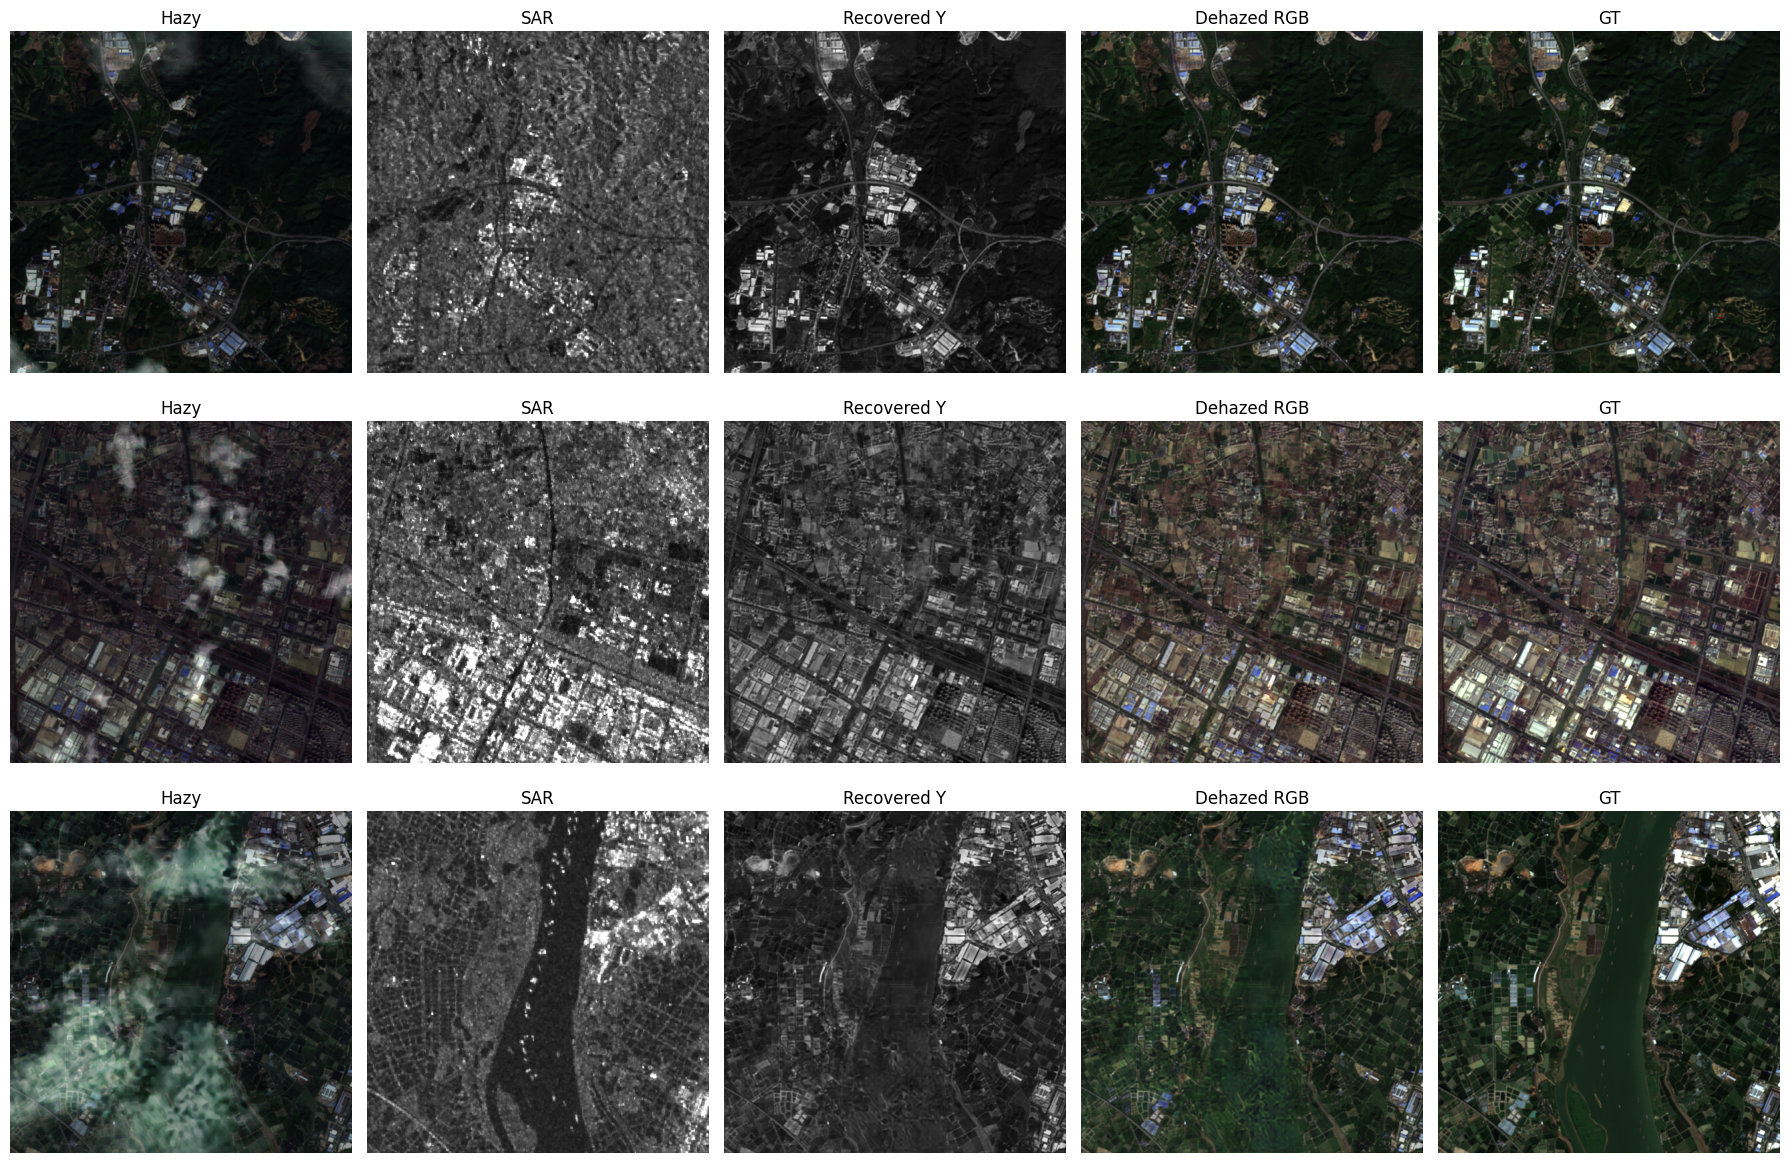

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

names = sorted((RESULT_DIR / "rgb").glob("*.png"))[:3]
fig, axes = plt.subplots(len(names), 5, figsize=(18, 4*len(names)), squeeze=False)
for row, prediction in enumerate(names):
    paths = [
        DATA_ROOT / "test" / "hazy" / prediction.name,
        DATA_ROOT / "test" / "SAR" / prediction.name,
        RESULT_DIR / "gray" / prediction.name,
        prediction,
        DATA_ROOT / "test" / "GT" / prediction.name,
    ]
    for col, (title, path) in enumerate(zip(["Hazy", "SAR", "Recovered Y", "Dehazed RGB", "GT"], paths)):
        with Image.open(path) as image:
            axes[row, col].imshow(image.copy(), cmap="gray" if col in (1, 2) else None)
        axes[row, col].set_title(title)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()


## Optional: score exported PNGs

This provides 8-bit image-file scores for comparison with pipelines that evaluate saved predictions. Small differences from `infer.py` metrics are expected because PNG export quantizes the predictions.


In [6]:
subprocess.run([
    sys.executable, "evaluate.py",
    "--predictions", str(RESULT_DIR / "rgb"),
    "--targets", str(DATA_ROOT / "test" / "GT"),
    "--output-dir", str(RESULT_DIR / "png_metrics"),
    "--device", "cuda",
], cwd=REPO_DIR, check=True)


{
  "images": 2000,
  "metric_protocol": "8-bit PNG RGB, full image, no shaving; Gaussian valid SSIM; mean per-image; RGB SAM degrees; ERGAS ratio=1",
  "mean": {
    "psnr": 23.296723514080046,
    "ssim": 0.8336707129478454,
    "mae": 0.05579639095067978,
    "sam_deg": 4.21277945959568,
    "ergas": 35.940833028793335
  }
}


CompletedProcess(args=['/usr/bin/python3', 'evaluate.py', '--predictions', '/kaggle/working/results/sar_gray_color/rgb', '--targets', '/kaggle/input/datasets/markosumire/mrshaze/MRSHaze/test/GT', '--output-dir', '/kaggle/working/results/sar_gray_color/png_metrics', '--device', 'cuda'], returncode=0)